# LE10 - Graphlets in Football Networks

**Graphlets** are small, connected subgraphs typically containing 2 to 5 nodes. They capture fine-grained structural patterns that traditional metrics miss.

### Applications in Football Networks

**Network Comparison (RGFD)**:
- Compare structural similarity between different team pass networks
- Identify teams with similar tactical structures

**Node Comparison (GDV)**:
- Find structurally similar players within a network
- Identify players with similar tactical roles regardless of position

### Core Concepts

**Graphlets**: All unique ways to connect a specific number of nodes
- 2-5 nodes: 30 different graphlets ($G_0$ to $G_{29}$)
- Capture local structural patterns (triangles, paths, stars, etc.)

**Orbits**: Unique positions within graphlets
- 73 different orbits across all graphlets
- Nodes at same orbit = structurally equivalent position

### Our Approach

1. Count graphlets in networks (RGFD for network comparison)
2. Calculate Graphlet Degree Vectors (GDV for node comparison)
3. Visualize structural similarities

In [3]:
# Import required libraries
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from typing import Set, Dict, List, Tuple
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.common import load_json_fixed, setup_logger
from src.config import (
    DATA_DIR,
    PASS_NETWORKS_DIR,
    MATCH_NETWORKS_DIR
)

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print("Imports successful!")
print(f"NetworkX version: {nx.__version__}")

Imports successful!
NetworkX version: 3.6.1


In [10]:
# Load networks
print("=== Loading Networks ===\n")

# Pass Network (directed, weighted) Germany
pass_network_path1 = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass_dir = nx.read_gexf(pass_network_path1)
print(f"Pass Network (Germany): {G_pass_dir.number_of_nodes()} nodes, {G_pass_dir.number_of_edges()} edges")

# Pass Network (directed, weighted) France
pass_network_path2 = PASS_NETWORKS_DIR / 'pass_network_France.gexf'
F_pass_dir = nx.read_gexf(pass_network_path2)
print(f"Pass Network (France): {F_pass_dir.number_of_nodes()} nodes, {F_pass_dir.number_of_edges()} edges")

# Convert to undirected since only constellation is important
G_pass = G_pass_dir.to_undirected()
F_pass = F_pass_dir.to_undirected()

# Match Network (directed) Germany
match_network_path1 = MATCH_NETWORKS_DIR / 'match_network_Germany.gexf'
G_match_dir = nx.read_gexf(match_network_path1)
print(f"Match Network (Germany): {G_match_dir.number_of_nodes()} nodes, {G_match_dir.number_of_edges()} edges")

# Match Network (directed) France
match_network_path2 = MATCH_NETWORKS_DIR / 'match_network_France.gexf'
F_match_dir = nx.read_gexf(match_network_path2)
print(f"Match Network (France): {F_match_dir.number_of_nodes()} nodes, {F_match_dir.number_of_edges()} edges")

# Convert to undirected
G_match = G_match_dir.to_undirected()
F_match = F_match_dir.to_undirected()

print("\nNetworks loaded successfully!")

=== Loading Networks ===

Pass Network (Germany): 473 nodes, 8786 edges
Pass Network (France): 541 nodes, 10235 edges
Match Network (Germany): 18 nodes, 306 edges
Match Network (France): 20 nodes, 380 edges

Networks loaded successfully!


For this chapter it was decided to compare the graphlets of the biggest connected component of Germany with the one from France. 

In [11]:
# only biggest connected component
# Germany pass network
components_g_pass = list(nx.connected_components(G_pass))
component_sizes_g_pass = [len(c) for c in components_g_pass]
print("Sizes of connected components:", component_sizes_g_pass)
print(f"\nGermany Pass Network: {len(components_g_pass)} components")

if len(components_g_pass) > 1:
    largest_cc_g_pass = max(components_g_pass, key=len)
    G_pass_gcc = G_pass.subgraph(largest_cc_g_pass).copy()
    G_pass_dir_gcc = G_pass_dir.subgraph(largest_cc_g_pass).copy()
else:
    G_pass_gcc = G_pass
    G_pass_dir_gcc = G_pass_dir

print(f"Using: {G_pass_gcc.number_of_nodes()} nodes")
print("\nReady for analysis!")

# Germany match network
components_match_g = list(nx.connected_components(G_match))
component_sizes_g_match = [len(c) for c in components_match_g]
print("Sizes of connected components:", component_sizes_g_match)
print(f"\nGermany Match Network: {len(components_match_g)} components")

if len(components_match_g) > 1:
    largest_cc_match = max(components_match_g, key=len)
    G_match_gcc = G_match.subgraph(largest_cc_match).copy()
    G_match_dir_gcc = G_match_dir.subgraph(largest_cc_match).copy()
else:
    G_match_gcc = G_match
    G_match_dir_gcc = G_match_dir

print(f"Using: {G_match_gcc.number_of_nodes()} nodes")
print("\nReady for analysis!")


# France pass network
components_f_pass = list(nx.connected_components(F_pass))
component_sizes_f_pass = [len(c) for c in components_f_pass]
print("Sizes of connected components:", component_sizes_f_pass)
print(f"\nFrance pass Network: {len(components_f_pass)} components")

if len(components_f_pass) > 1:
    largest_cc_f_pass = max(components_f_pass, key=len)
    F_pass_gcc = F_pass.subgraph(largest_cc_f_pass).copy()
    F_pass_dir_gcc = F_pass_dir.subgraph(largest_cc_f_pass).copy()
else:
    F_pass_gcc = F_pass
    F_pass_dir_gcc = F_pass_dir

print(f"Using: {F_pass_gcc.number_of_nodes()} nodes")
print("\nReady for analysis!")

# France match network
components_match_f = list(nx.connected_components(F_match))
component_sizes_f_match = [len(c) for c in components_match_f]
print("Sizes of connected components:", component_sizes_f_match)
print(f"\nFrance Match Network: {len(components_match_f)} components")

if len(components_match_f) > 1:
    largest_cc_match_f = max(components_match_f, key=len)
    F_match_gcc = F_match.subgraph(largest_cc_match_f).copy()
    F_match_dir_gcc = F_match_dir.subgraph(largest_cc_match).copy()
else:
    F_match_gcc = F_match
    F_match_dir_gcc = F_match_dir

print(f"Using: {F_match_gcc.number_of_nodes()} nodes")
print("\nReady for analysis!")

Sizes of connected components: [283, 29, 26, 27, 24, 27, 28, 29]

Germany Pass Network: 8 components
Using: 283 nodes

Ready for analysis!
Sizes of connected components: [18]

Germany Match Network: 1 components
Using: 18 nodes

Ready for analysis!
Sizes of connected components: [215, 52, 54, 23, 30, 54, 36, 77]

France pass Network: 8 components
Using: 215 nodes

Ready for analysis!
Sizes of connected components: [20]

France Match Network: 1 components
Using: 20 nodes

Ready for analysis!


## 2. Graphlets and Orbits

### Graphlet Definition

A **graphlet** is a small, connected subgraph that captures a specific structural pattern.

**Example 3-node graphlets:**

**$G_1$ (Path)**: Two edges in a line
```
o---o---o
```

**$G_2$ (Triangle)**: Three edges forming a triangle
```
o---o
 \ /
  o
```

**Total graphlets by size:**
- 2 nodes: 1 graphlet ($G_0$)
- 3 nodes: 2 graphlets ($G_1, G_2$)
- 4 nodes: 6 graphlets
- 5 nodes: 21 graphlets
- **Total: 30 graphlets**

### Orbits

**Orbits** identify structurally equivalent positions within graphlets.

**Example - $G_1$ (Path)**:
- **End positions** (orbit 1): Connected to 1 node, which connects to another
- **Center position** (orbit 2): Connected to 2 nodes that aren't connected to each other

**Total across all graphlets**: 73 unique orbits (numbered 0-72)

**Why orbits matter**: Two nodes with same degree can have completely different structural roles.

In [30]:
from itertools import combinations

def count_3node_graphlets(G):
    """
    Count 3-node graphlets in network.
    
    3-node graphlets:
    - G1: Path (2 edges)
    - G2: Triangle (3 edges)
    
    Parameters:
    -----------
    G : networkx.Graph
        Undirected network
    
    Returns:
    --------
    dict : {graphlet_id: count}
    """
    counts = {'G1': 0, 'G2': 0}
    
    # Iterate over all 3-node combinations
    nodes = list(G.nodes())
    for triplet in combinations(nodes, 3):
        subgraph = G.subgraph(triplet)
        num_edges = subgraph.number_of_edges()
        
        if num_edges == 2:
            counts['G1'] += 1  # Path
        elif num_edges == 3:
            counts['G2'] += 1  # Triangle
    
    return counts


def count_4node_graphlets(G):
    """
    Count 4-node graphlets in network.
    
    4-node graphlets (6 types):
    - G3: 3 edges, no triangles (path/fork patterns)
    - G4: 3 edges forming Y-shape
    - G5: 4 edges, linear chain
    - G6: 4 edges, triangle + 1
    - G7: 5 edges, diamond
    - G8: 6 edges, complete graph (K4)
    
    Note: Simplified classification
    
    Parameters:
    -----------
    G : networkx.Graph
        Undirected network
    
    Returns:
    --------
    dict : {graphlet_id: count}
    """
    counts = {f'G{i}': 0 for i in range(3, 9)}
    
    nodes = list(G.nodes())
    for quartet in combinations(nodes, 4):
        subgraph = G.subgraph(quartet)
        num_edges = subgraph.number_of_edges()
        num_triangles = sum(nx.triangles(subgraph).values()) // 3
        
        if num_edges == 3:
            if num_triangles == 0:
                counts['G3'] += 1  # No triangle
            else:
                counts['G4'] += 1  # Y-shape
        elif num_edges == 4:
            if num_triangles == 0:
                counts['G5'] += 1  # Linear/fork
            else:
                counts['G6'] += 1  # Triangle + tail
        elif num_edges == 5:
            counts['G7'] += 1  # Diamond
        elif num_edges == 6:
            counts['G8'] += 1  # Complete K4
    
    return counts


def count_all_graphlets(G, max_size=4):
    """
    Count all graphlets up to specified size.
    
    Parameters:
    -----------
    G : networkx.Graph
        Undirected network
    max_size : int
        Maximum graphlet size (3 or 4)
    
    Returns:
    --------
    dict : Combined graphlet counts
    """
    print(f"Counting graphlets (this may take a moment for large networks)...")
    
    all_counts = {}
    
    # 3-node graphlets
    counts_3 = count_3node_graphlets(G)
    all_counts.update(counts_3)
    
    # 4-node graphlets (if requested)
    if max_size >= 4:
        counts_4 = count_4node_graphlets(G)
        all_counts.update(counts_4)
    
    return all_counts

def visualize_graphlet_distribution(counts, network_name="Network", title_suffix=""):
    """
    Visualize graphlet frequency distribution for a single network.
    """
    graphlets = sorted(counts.keys(), key=lambda x: int(x[1:]))
    frequencies = [counts[g] for g in graphlets]
    total = sum(frequencies)
    percentages = [f / total * 100 if total > 0 else 0 for f in frequencies]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Absolute counts
    colors = plt.cm.viridis(np.linspace(0, 1, len(graphlets)))
    bars1 = ax1.bar(graphlets, frequencies, color=colors, alpha=0.7, edgecolor='black')
    ax1.set_xlabel('Graphlet Type', fontsize=12)
    ax1.set_ylabel('Count', fontsize=12)
    ax1.set_title(f'Graphlet Counts - {network_name}{title_suffix}', 
                  fontsize=13, fontweight='bold')
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Relative percentages
    bars2 = ax2.bar(graphlets, percentages, color=colors, alpha=0.7, edgecolor='black')
    ax2.set_xlabel('Graphlet Type', fontsize=12)
    ax2.set_ylabel('Percentage (%)', fontsize=12)
    ax2.set_title(f'Graphlet Distribution - {network_name}{title_suffix}', 
                  fontsize=13, fontweight='bold')
    ax2.tick_params(axis='x', rotation=45)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax = bar.axes
                ax.text(bar.get_x() + bar.get_width()/2., height,
                       f'{int(height)}' if bars == bars1 else f'{height:.1f}%',
                       ha='center', va='bottom', fontsize=9)
    
    plt.tight_layout()
    return fig

Since checking all Graphlets for bigger networks takes a log of time only grphlets with 3 nodes will be analized here. This way the code runs within a resoanable timeframe. 


GRAPHLET ANALYSIS - Germany Pass Network (GCC)

Network: 283 nodes, 2894 edges

Counting 3-node and 4-node graphlets...
Counting graphlets (this may take a moment for large networks)...

Graphlet counts:
Graphlet   Count      Percentage  
-----------------------------------
G1         11401      40.10       %
G2         17030      59.90       %

Total graphlets: 28,431

Top 3 most common patterns:
  G2: 17,030 (59.9%)
  G1: 11,401 (40.1%)


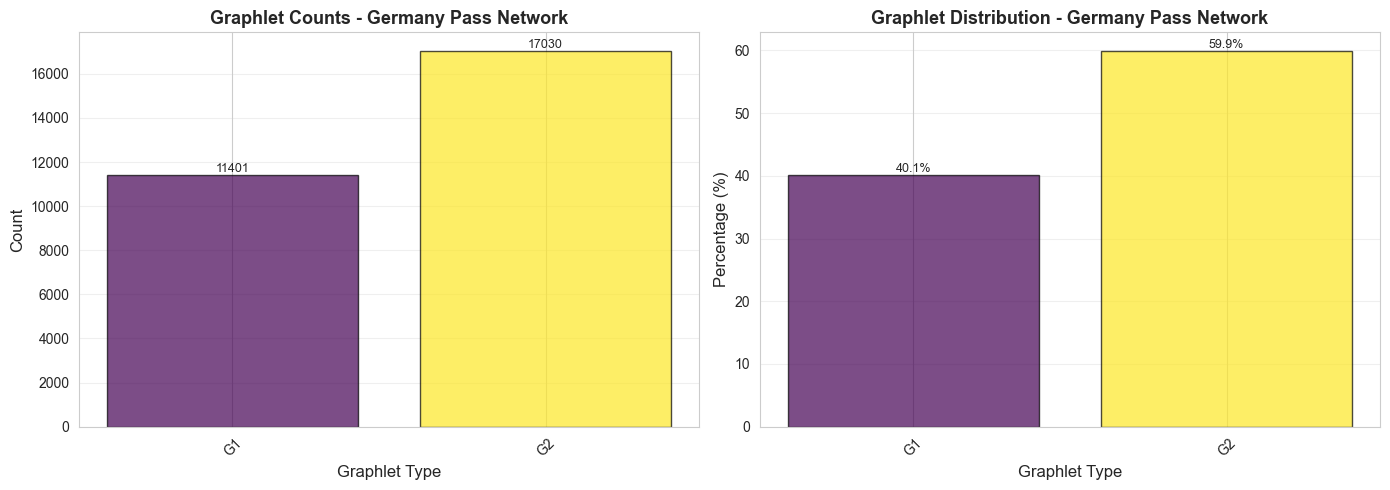

In [31]:
print("\n" + "=" * 70)
print("GRAPHLET ANALYSIS - Germany Pass Network (GCC)")
print("=" * 70)

print(f"\nNetwork: {G_pass_gcc.number_of_nodes()} nodes, "
      f"{G_pass_gcc.number_of_edges()} edges")

# Count graphlets
print("\nCounting 3-node and 4-node graphlets...")
graphlets_germany_pass = count_all_graphlets(G_pass_gcc, max_size=3)

print("\nGraphlet counts:")
total_g = sum(graphlets_germany_pass.values())
print(f"{'Graphlet':<10} {'Count':<10} {'Percentage':<12}")
print("-" * 35)
for g in sorted(graphlets_germany_pass.keys(), key=lambda x: int(x[1:])):
    count = graphlets_germany_pass[g]
    pct = count / total_g * 100 if total_g > 0 else 0
    print(f"{g:<10} {count:<10} {pct:<12.2f}%")

print(f"\nTotal graphlets: {total_g:,}")

# Dominant patterns
sorted_g = sorted(graphlets_germany_pass.items(), key=lambda x: x[1], reverse=True)
print(f"\nTop 3 most common patterns:")
for g, count in sorted_g[:3]:
    pct = count / total_g * 100
    print(f"  {g}: {count:,} ({pct:.1f}%)")

# Visualize
fig_germany = visualize_graphlet_distribution(graphlets_germany_pass, 
                                              "Germany Pass Network")
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'graphlets_germany_pass.png',
            dpi=300, bbox_inches='tight')
plt.show()


GRAPHLET ANALYSIS - France Pass Network (GCC)

Network: 215 nodes, 2214 edges

Counting 3-node and 4-node graphlets...
Counting graphlets (this may take a moment for large networks)...

Graphlet counts:
Graphlet   Count      Percentage  
-----------------------------------
G1         8772       40.30       %
G2         12995      59.70       %

Total graphlets: 21,767

Top 3 most common patterns:
  G2: 12,995 (59.7%)
  G1: 8,772 (40.3%)


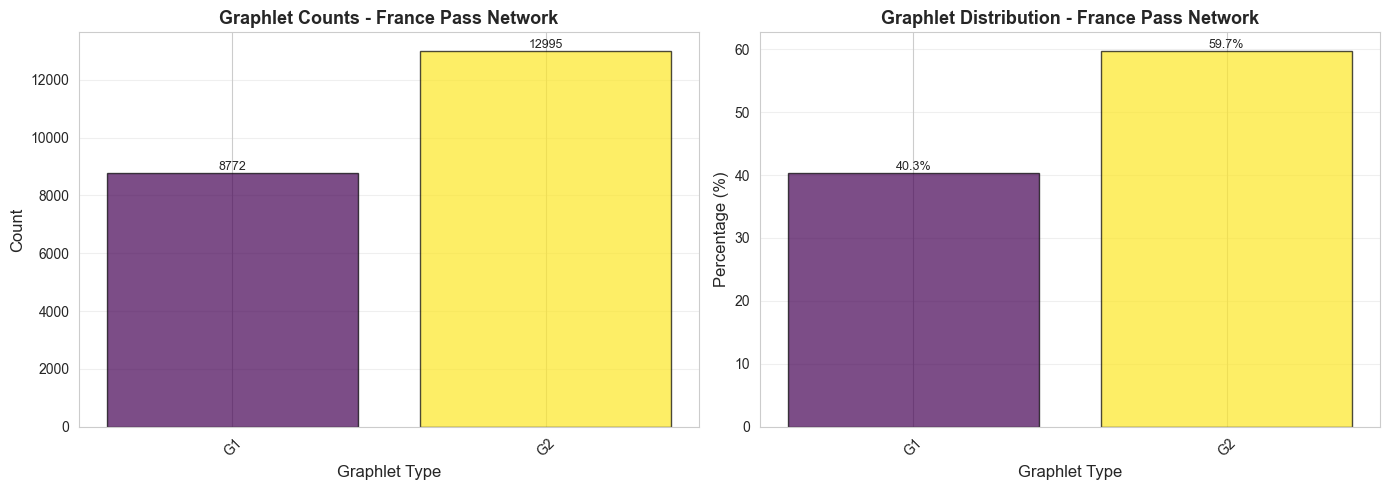

In [32]:
print("\n" + "=" * 70)
print("GRAPHLET ANALYSIS - France Pass Network (GCC)")
print("=" * 70)

print(f"\nNetwork: {F_pass_gcc.number_of_nodes()} nodes, "
      f"{F_pass_gcc.number_of_edges()} edges")

# Count graphlets
print("\nCounting 3-node and 4-node graphlets...")
graphlets_france_pass = count_all_graphlets(F_pass_gcc, max_size=3)

print("\nGraphlet counts:")
total_f = sum(graphlets_france_pass.values())
print(f"{'Graphlet':<10} {'Count':<10} {'Percentage':<12}")
print("-" * 35)
for g in sorted(graphlets_france_pass.keys(), key=lambda x: int(x[1:])):
    count = graphlets_france_pass[g]
    pct = count / total_f * 100 if total_f > 0 else 0
    print(f"{g:<10} {count:<10} {pct:<12.2f}%")

print(f"\nTotal graphlets: {total_f:,}")

# Dominant patterns
sorted_f = sorted(graphlets_france_pass.items(), key=lambda x: x[1], reverse=True)
print(f"\nTop 3 most common patterns:")
for g, count in sorted_f[:3]:
    pct = count / total_f * 100
    print(f"  {g}: {count:,} ({pct:.1f}%)")

# Visualize
fig_france = visualize_graphlet_distribution(graphlets_france_pass, 
                                            "France Pass Network")
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'graphlets_france_pass.png',
            dpi=300, bbox_inches='tight')
plt.show()


COMPARING GERMANY VS FRANCE - Pass Networks


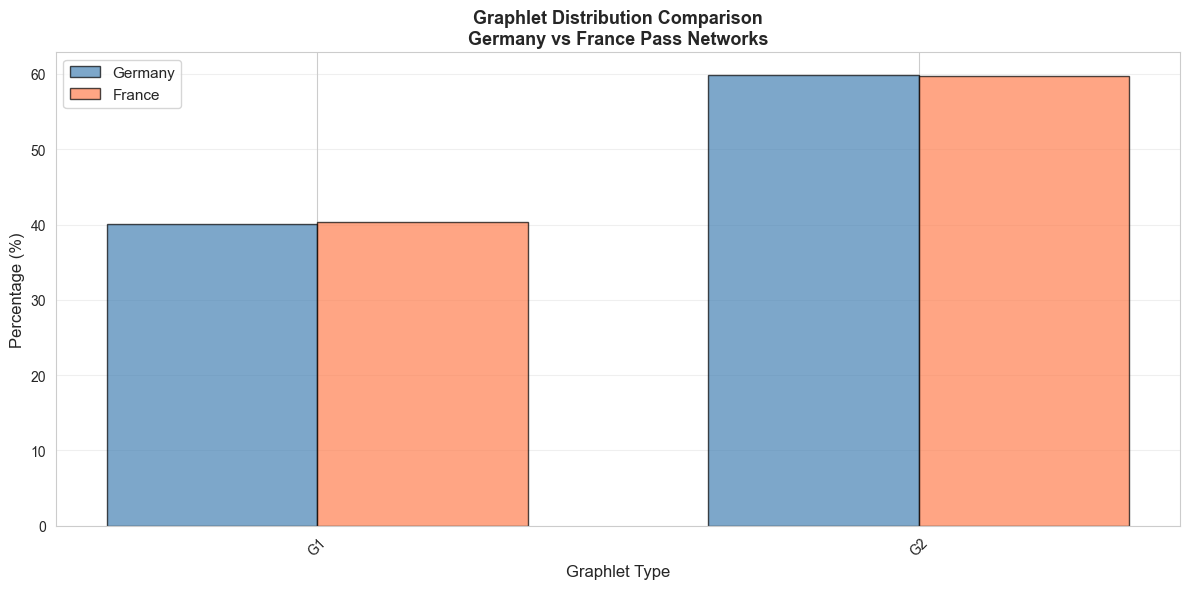


Key structural differences:
Graphlet   Germany %    France %     Difference  
--------------------------------------------------
G1         40.10        40.30              -0.20
G2         59.90        59.70              +0.20

Largest structural differences:
  G1: France has 0.2% more
  G2: Germany has 0.2% more


In [33]:
print("\n" + "=" * 70)
print("COMPARING GERMANY VS FRANCE - Pass Networks")
print("=" * 70)

# Prepare comparison data
all_graphlets = sorted(set(graphlets_germany_pass.keys()) | 
                      set(graphlets_france_pass.keys()), 
                      key=lambda x: int(x[1:]))

percentages_g = [graphlets_germany_pass.get(g, 0) / max(total_g, 1) * 100 
                 for g in all_graphlets]
percentages_f = [graphlets_france_pass.get(g, 0) / max(total_f, 1) * 100 
                 for g in all_graphlets]

# Create comparison plot
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(all_graphlets))
width = 0.35

bars1 = ax.bar(x - width/2, percentages_g, width, label='Germany', 
               alpha=0.7, edgecolor='black', color='steelblue')
bars2 = ax.bar(x + width/2, percentages_f, width, label='France',
               alpha=0.7, edgecolor='black', color='coral')

ax.set_xlabel('Graphlet Type', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_title('Graphlet Distribution Comparison\nGermany vs France Pass Networks',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(all_graphlets, rotation=45)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'graphlets_comparison_pass.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Analyze differences
print("\nKey structural differences:")
print(f"{'Graphlet':<10} {'Germany %':<12} {'France %':<12} {'Difference':<12}")
print("-" * 50)
for i, g in enumerate(all_graphlets):
    diff = percentages_g[i] - percentages_f[i]
    print(f"{g:<10} {percentages_g[i]:<12.2f} {percentages_f[i]:<12.2f} {diff:>+11.2f}")

# Biggest differences
diffs = [(g, percentages_g[i] - percentages_f[i]) 
         for i, g in enumerate(all_graphlets)]
diffs_sorted = sorted(diffs, key=lambda x: abs(x[1]), reverse=True)

print(f"\nLargest structural differences:")
for g, diff in diffs_sorted[:3]:
    if diff > 0:
        print(f"  {g}: Germany has {abs(diff):.1f}% more")
    else:
        print(f"  {g}: France has {abs(diff):.1f}% more")


GRAPHLET ANALYSIS - Match Networks

Germany Match Network: 18 nodes, 153 edges
Counting graphlets...
Counting graphlets (this may take a moment for large networks)...

Graphlet distribution:
  G1: 0 (0.0%)
  G2: 816 (21.1%)
  G3: 0 (0.0%)
  G4: 0 (0.0%)
  G5: 0 (0.0%)
  G6: 0 (0.0%)
  G7: 0 (0.0%)
  G8: 3060 (78.9%)

France Match Network: 20 nodes, 190 edges
Counting graphlets...
Counting graphlets (this may take a moment for large networks)...

Graphlet distribution:
  G1: 0 (0.0%)
  G2: 1140 (19.0%)
  G3: 0 (0.0%)
  G4: 0 (0.0%)
  G5: 0 (0.0%)
  G6: 0 (0.0%)
  G7: 0 (0.0%)
  G8: 4845 (81.0%)


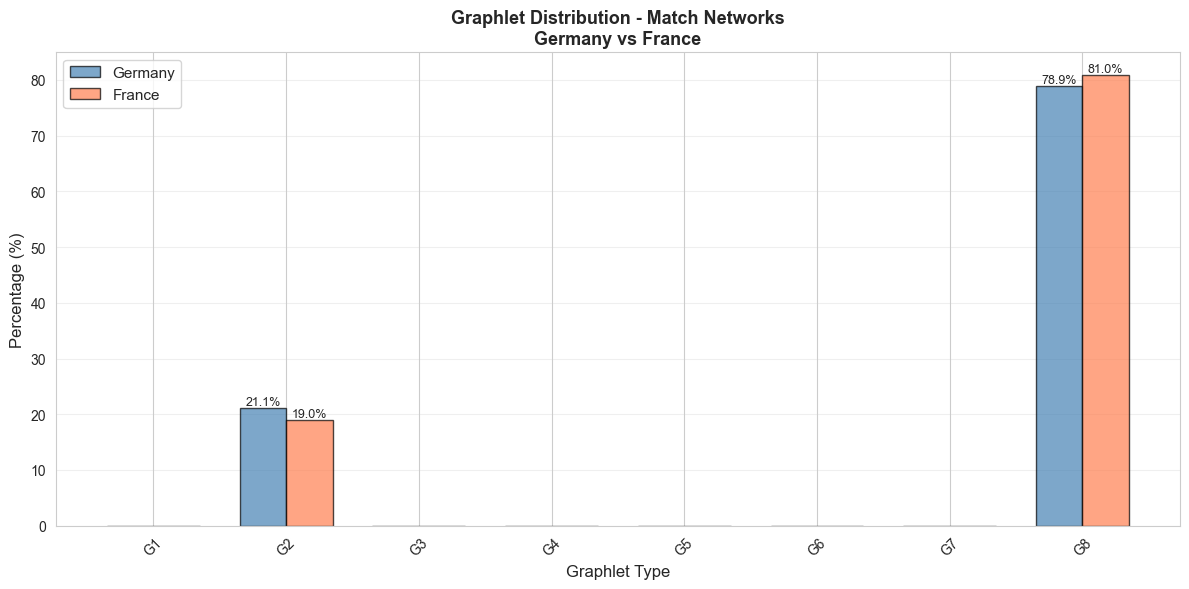

In [34]:
print("\n" + "=" * 70)
print("GRAPHLET ANALYSIS - Match Networks")
print("=" * 70)

# Germany match network
print(f"\nGermany Match Network: {G_match_gcc.number_of_nodes()} nodes, "
      f"{G_match_gcc.number_of_edges()} edges")
print("Counting graphlets...")
graphlets_germany_match = count_all_graphlets(G_match_gcc, max_size=4)  # 3-node only for smaller networks

total_gm = sum(graphlets_germany_match.values())
print("\nGraphlet distribution:")
for g in sorted(graphlets_germany_match.keys(), key=lambda x: int(x[1:])):
    count = graphlets_germany_match[g]
    pct = count / total_gm * 100 if total_gm > 0 else 0
    print(f"  {g}: {count} ({pct:.1f}%)")

# France match network
print(f"\nFrance Match Network: {F_match_gcc.number_of_nodes()} nodes, "
      f"{F_match_gcc.number_of_edges()} edges")
print("Counting graphlets...")
graphlets_france_match = count_all_graphlets(F_match_gcc, max_size=4)

total_fm = sum(graphlets_france_match.values())
print("\nGraphlet distribution:")
for g in sorted(graphlets_france_match.keys(), key=lambda x: int(x[1:])):
    count = graphlets_france_match[g]
    pct = count / total_fm * 100 if total_fm > 0 else 0
    print(f"  {g}: {count} ({pct:.1f}%)")

# Visualize match networks comparison
all_match_graphlets = sorted(
    set(graphlets_germany_match.keys()) | set(graphlets_france_match.keys()),
    key=lambda x: int(x[1:])
)

g_match_pcts = [graphlets_germany_match.get(g, 0) / max(total_gm, 1) * 100 
                for g in all_match_graphlets]
f_match_pcts = [graphlets_france_match.get(g, 0) / max(total_fm, 1) * 100 
                for g in all_match_graphlets]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(all_match_graphlets))
width = 0.35

bars1 = ax.bar(x - width/2, g_match_pcts, width, label='Germany', 
               alpha=0.7, edgecolor='black', color='steelblue')
bars2 = ax.bar(x + width/2, f_match_pcts, width, label='France',
               alpha=0.7, edgecolor='black', color='coral')

ax.set_xlabel('Graphlet Type', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_title('Graphlet Distribution - Match Networks\nGermany vs France',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(all_match_graphlets, rotation=45)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars for non-zero values
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.1f}%',
                   ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'graphlets_comparison_match.png',
            dpi=300, bbox_inches='tight')
plt.show()

## 3. Relative Graphlet Frequency Distance (RGFD)

**RGFD** measures structural similarity between entire networks.

### Purpose

Compare networks based on structural composition, independent of size.

### Calculation Steps

**Step 1: Count total graphlets**

$$T(G) = \sum_{i=1}^{29} N_i(G)$$

where $N_i(G)$ = count of graphlet $G_i$ in network (excludes $G_0$)

**Step 2: Calculate log-weighted frequency**

$$F_i(G) = -\log\left(\frac{N_i(G)}{T(G)}\right)$$

The negative log makes **rare graphlets more important** than common ones.

**Step 3: Compute distance**

$$D(G, H) = \sum_{i=1}^{29} |F_i(G) - F_i(H)|$$

### Properties

- **Smaller distance** = more structurally similar
- **Size-independent**: Normalized by total count
- **Range**: $[0, \infty)$

### Interpretation

- $D < 2$: Very similar structures
- $D = 2-5$: Some structural differences
- $D > 5$: Fundamentally different structures

In [44]:
def calculate_rgfd(G1, G2, max_size=4):
    """
    Calculate Relative Graphlet Frequency Distance between two networks.
    
    RGFD measures structural similarity independent of network size.
    Lower values = more similar structures.
    
    Formula:
    D(G,H) = Σ |F_i(G) - F_i(H)|
    where F_i(G) = -log(N_i(G) / T(G))
    
    Parameters:
    G1, G2 : networkx.Graph
        Networks to compare
    max_size : int
        Maximum graphlet size
    
    Returns:
    dict : RGFD results
    """
    # Count graphlets in both networks
    counts1 = count_all_graphlets(G1, max_size=max_size)
    counts2 = count_all_graphlets(G2, max_size=max_size)
    
    # Total graphlets (excluding G0)
    total1 = sum(counts1.values())
    total2 = sum(counts2.values())
    
    # Calculate F_i (relative frequencies with log weighting)
    frequencies1 = {}
    frequencies2 = {}
    
    all_graphlets = set(counts1.keys()) | set(counts2.keys())
    
    for g in all_graphlets:
        # F_i = -log(N_i / T)
        # Add small epsilon to avoid log(0)
        freq1 = counts1.get(g, 0) / max(total1, 1)
        freq2 = counts2.get(g, 0) / max(total2, 1)
        
        frequencies1[g] = -np.log(freq1 + 1e-10)
        frequencies2[g] = -np.log(freq2 + 1e-10)
    
    # Calculate distance
    distance = sum(abs(frequencies1[g] - frequencies2[g]) for g in all_graphlets)
    
    return {
        'distance': distance,
        'counts1': counts1,
        'counts2': counts2,
        'frequencies1': frequencies1,
        'frequencies2': frequencies2,
        'total1': total1,
        'total2': total2
    }

def visualize_rgfd_comparison(rgfd_result, name1="Network 1", name2="Network 2"):
    """
    Visualize RGFD comparison between two networks.
    """
    counts1 = rgfd_result['counts1']
    counts2 = rgfd_result['counts2']
    
    # Prepare data
    all_graphlets = sorted(set(counts1.keys()) | set(counts2.keys()), 
                          key=lambda x: int(x[1:]))
    
    total1 = rgfd_result['total1']
    total2 = rgfd_result['total2']
    
    percentages1 = [counts1.get(g, 0) / max(total1, 1) * 100 for g in all_graphlets]
    percentages2 = [counts2.get(g, 0) / max(total2, 1) * 100 for g in all_graphlets]
    
    # Create comparison plot
    fig, ax = plt.subplots(figsize=(12, 6))
    
    x = np.arange(len(all_graphlets))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, percentages1, width, label=name1, 
                   alpha=0.7, edgecolor='black', color='steelblue')
    bars2 = ax.bar(x + width/2, percentages2, width, label=name2,
                   alpha=0.7, edgecolor='black', color='coral')
    
    ax.set_xlabel('Graphlet Type', fontsize=12)
    ax.set_ylabel('Percentage (%)', fontsize=12)
    ax.set_title(f'Graphlet Distribution Comparison\nRGFD = {rgfd_result["distance"]:.3f}',
                 fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(all_graphlets, rotation=45)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig


RGFD COMPARISON - Germany vs France Pass Networks

Calculating RGFD between Germany and France pass networks...
Counting graphlets (this may take a moment for large networks)...
Counting graphlets (this may take a moment for large networks)...

RGFD Distance: 0.008

Network sizes:
  Germany: 283 nodes, 2894 edges
  France:  215 nodes, 2214 edges

Total graphlets counted:
  Germany: 28,431
  France:  21,767

Graphlet frequency comparison:
Graphlet   Germany %    France %     F_i(G)       F_i(F)       |Difference|   
--------------------------------------------------------------------------------
G1         40.10        40.30        0.914        0.909        0.005          
G2         59.90        59.70        0.513        0.516        0.003          

Interpretation:
  Very similar structures (RGFD < 2)


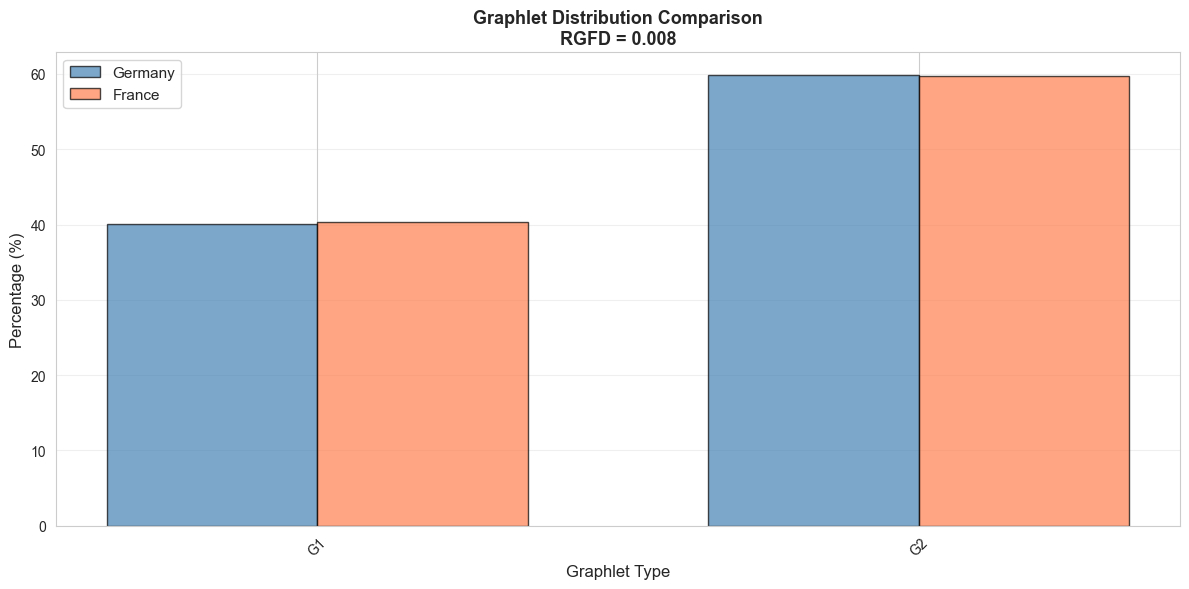

In [45]:
print("\n" + "=" * 70)
print("RGFD COMPARISON - Germany vs France Pass Networks")
print("=" * 70)

print("\nCalculating RGFD between Germany and France pass networks...")
rgfd_pass_result = calculate_rgfd(G_pass_gcc, F_pass_gcc, max_size=3)

print(f"\nRGFD Distance: {rgfd_pass_result['distance']:.3f}")

# Show the calculation breakdown
print(f"\nNetwork sizes:")
print(f"  Germany: {G_pass_gcc.number_of_nodes()} nodes, {G_pass_gcc.number_of_edges()} edges")
print(f"  France:  {F_pass_gcc.number_of_nodes()} nodes, {F_pass_gcc.number_of_edges()} edges")

print(f"\nTotal graphlets counted:")
print(f"  Germany: {rgfd_pass_result['total1']:,}")
print(f"  France:  {rgfd_pass_result['total2']:,}")

# Show frequency comparison
print(f"\nGraphlet frequency comparison:")
print(f"{'Graphlet':<10} {'Germany %':<12} {'France %':<12} {'F_i(G)':<12} {'F_i(F)':<12} {'|Difference|':<15}")
print("-" * 80)

for g in sorted(rgfd_pass_result['counts1'].keys(), key=lambda x: int(x[1:])):
    count_g = rgfd_pass_result['counts1'][g]
    count_f = rgfd_pass_result['counts2'][g]
    
    pct_g = count_g / rgfd_pass_result['total1'] * 100
    pct_f = count_f / rgfd_pass_result['total2'] * 100
    
    freq_g = rgfd_pass_result['frequencies1'][g]
    freq_f = rgfd_pass_result['frequencies2'][g]
    
    diff = abs(freq_g - freq_f)
    
    print(f"{g:<10} {pct_g:<12.2f} {pct_f:<12.2f} {freq_g:<12.3f} {freq_f:<12.3f} {diff:<15.3f}")

# Interpretation
print(f"\nInterpretation:")
if rgfd_pass_result['distance'] < 2:
    print(f"  Very similar structures (RGFD < 2)")
elif rgfd_pass_result['distance'] < 5:
    print(f"  Some structural differences (RGFD = 2-5)")
else:
    print(f"  Fundamentally different structures (RGFD > 5)")

# Visualize comparison
fig_rgfd_pass = visualize_rgfd_comparison(rgfd_pass_result, 
                                          "Germany", "France")
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'rgfd_pass_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()


RGFD COMPARISON - Germany vs France Match Networks

Calculating RGFD between Germany and France match networks...
Counting graphlets (this may take a moment for large networks)...
Counting graphlets (this may take a moment for large networks)...

RGFD Distance: 0.125

Network sizes:
  Germany: 18 nodes, 153 edges
  France:  20 nodes, 190 edges

Total graphlets:
  Germany: 3,876
  France:  5,985

Graphlet distribution (non-zero only):
Graphlet   Germany %    France %    
-----------------------------------
G2         21.05        19.05       
G8         78.95        80.95       

Interpretation:
  Very similar tournament structures (RGFD < 2)
  Both networks have comparable match patterns


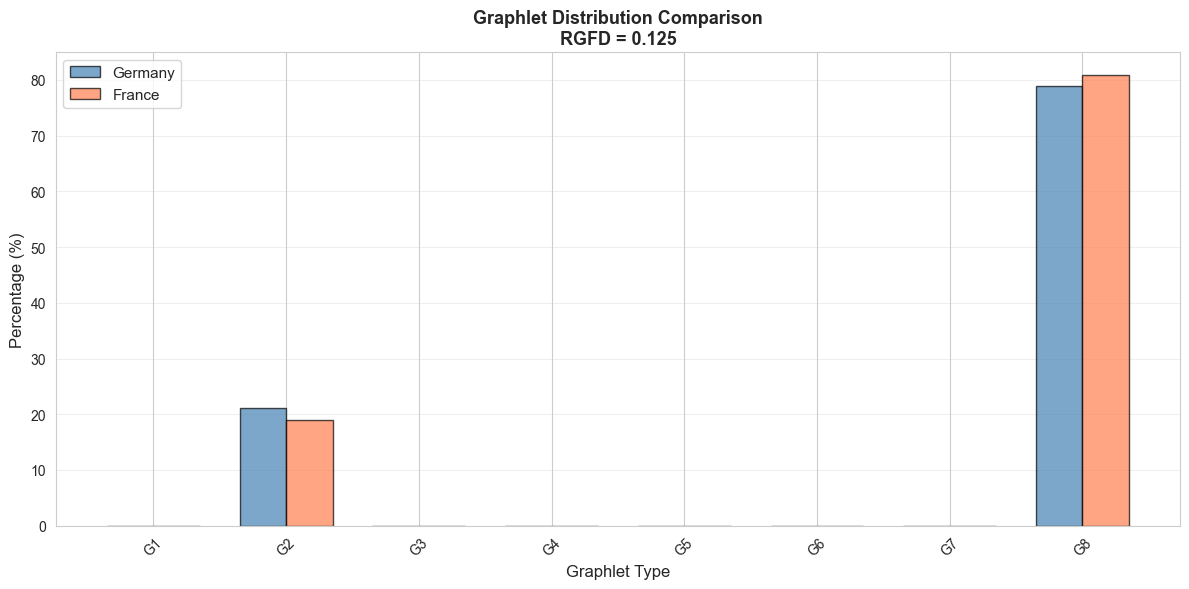

In [46]:
print("\n" + "=" * 70)
print("RGFD COMPARISON - Germany vs France Match Networks")
print("=" * 70)

print("\nCalculating RGFD between Germany and France match networks...")
rgfd_match_result = calculate_rgfd(G_match_gcc, F_match_gcc, max_size=4)

print(f"\nRGFD Distance: {rgfd_match_result['distance']:.3f}")

print(f"\nNetwork sizes:")
print(f"  Germany: {G_match_gcc.number_of_nodes()} nodes, {G_match_gcc.number_of_edges()} edges")
print(f"  France:  {F_match_gcc.number_of_nodes()} nodes, {F_match_gcc.number_of_edges()} edges")

print(f"\nTotal graphlets:")
print(f"  Germany: {rgfd_match_result['total1']:,}")
print(f"  France:  {rgfd_match_result['total2']:,}")

# Show non-zero graphlets only
print(f"\nGraphlet distribution (non-zero only):")
print(f"{'Graphlet':<10} {'Germany %':<12} {'France %':<12}")
print("-" * 35)

for g in sorted(rgfd_match_result['counts1'].keys(), key=lambda x: int(x[1:])):
    count_g = rgfd_match_result['counts1'].get(g, 0)
    count_f = rgfd_match_result['counts2'].get(g, 0)
    
    if count_g > 0 or count_f > 0:
        pct_g = count_g / rgfd_match_result['total1'] * 100
        pct_f = count_f / rgfd_match_result['total2'] * 100
        print(f"{g:<10} {pct_g:<12.2f} {pct_f:<12.2f}")

# Interpretation
print(f"\nInterpretation:")
if rgfd_match_result['distance'] < 2:
    print(f"  Very similar tournament structures (RGFD < 2)")
    print(f"  Both networks have comparable match patterns")
elif rgfd_match_result['distance'] < 5:
    print(f"  Some differences in tournament structure")
else:
    print(f"  Different tournament structures")

# Visualize
fig_rgfd_match = visualize_rgfd_comparison(rgfd_match_result,
                                           "Germany", "France")
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'rgfd_match_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

## 4. Graphlet Degree Vector (GDV)

**GDV** captures the local structural signature of individual nodes.

### Definition

For node $v$, GDV is a vector counting how many times $v$ appears in each orbit:

$$\text{GDV}(v) = [d_0(v), d_1(v), d_2(v), ..., d_{72}(v)]$$

where $d_i(v)$ = number of times node $v$ touches orbit $i$

### Purpose

Find nodes with similar **local structural patterns**, even if they're in different parts of the network.

### Example

For 2-3 node graphlets (4 orbits):
- Node with many triangles → high orbit 3 count
- Node that bridges clusters → high orbit 2 count (center of paths)
- Peripheral node → high orbit 1 count (end of paths)

### Comparing Nodes

**Distance between nodes:**

$$\text{distance}(u,v) = ||\text{GDV}(u) - \text{GDV}(v)||$$

**Similar GDVs** → similar structural roles

## Visualization with t-SNE

### Dimensionality Reduction

GDVs are high-dimensional (up to 73 dimensions). We reduce to 2D for visualization.

**t-SNE** (t-Distributed Stochastic Neighbor Embedding):
- Reduces dimensions while preserving similarity
- Similar nodes cluster together in 2D space

### Interpretation

**Nodes close together** in 2D plot → structurally similar
**Nodes far apart** → different structural roles

**Example patterns:**
- Central playmakers cluster together
- Wing players form another cluster
- Defensive players in different region

This reveals **structural equivalence** that position or centrality alone doesn't show.

In [78]:
from scipy.spatial.distance import euclidean, cosine
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

def calculate_gdv_3node(G):
    """
    Calculate Graphlet Degree Vector for all nodes using 3-node graphlets.
    
    Orbits (simplified):
    - orbit_0: Degree (simple edge count)
    - orbit_1: End of path (connected to node that connects to another)
    - orbit_2: Center of path (connects two nodes that aren't connected)
    - orbit_3: Part of triangle (all three connected)
    
    Parameters:
    -----------
    G : networkx.Graph
        Undirected network
    
    Returns:
    --------
    dict : {node: [orbit_0, orbit_1, orbit_2, orbit_3]}
    """
    gdv = {node: [0, 0, 0, 0] for node in G.nodes()}
    
    print("Calculating GDV for all nodes...")
    
    # Orbit 0: Simply the degree
    for node in G.nodes():
        gdv[node][0] = G.degree(node)
    
    # Process all triangles and paths
    for node in G.nodes():
        neighbors = list(G.neighbors(node))
        
        for i, neighbor1 in enumerate(neighbors):
            for neighbor2 in neighbors[i+1:]:
                if G.has_edge(neighbor1, neighbor2):
                    # Triangle: node, neighbor1, neighbor2
                    gdv[node][3] += 1
                    gdv[neighbor1][3] += 1
                    gdv[neighbor2][3] += 1
                else:
                    # Path: neighbor1 - node - neighbor2
                    gdv[node][2] += 1  # Center of path
                    gdv[neighbor1][1] += 1  # End of path
                    gdv[neighbor2][1] += 1  # End of path
    
    return gdv


def normalize_gdv(gdv_dict):
    """
    Normalize GDV vectors to [0, 1] range.
    
    Parameters:
    -----------
    gdv_dict : dict
        {node: GDV vector}
    
    Returns:
    --------
    dict : Normalized GDV vectors
    """
    # Get all vectors
    vectors = np.array(list(gdv_dict.values()))
    
    # Normalize each orbit dimension separately
    max_vals = vectors.max(axis=0)
    max_vals[max_vals == 0] = 1  # Avoid division by zero
    
    normalized = {}
    for node, vec in gdv_dict.items():
        normalized[node] = list(np.array(vec) / max_vals)
    
    return normalized


def find_similar_nodes(gdv_dict, target_node, top_k=5, metric='euclidean'):
    """
    Find nodes with most similar GDV to target node.
    
    Parameters:
    -----------
    gdv_dict : dict
        {node: GDV vector}
    target_node : node
        Node to compare against
    top_k : int
        Number of similar nodes to return
    metric : str
        'euclidean' or 'cosine'
    
    Returns:
    --------
    list : [(node, distance), ...] sorted by similarity
    """
    if target_node not in gdv_dict:
        return []
    
    target_vec = np.array(gdv_dict[target_node])
    distances = []
    
    for node, vec in gdv_dict.items():
        if node == target_node:
            continue
        
        node_vec = np.array(vec)
        
        if metric == 'euclidean':
            dist = euclidean(target_vec, node_vec)
        elif metric == 'cosine':
            dist = cosine(target_vec, node_vec)
        else:
            dist = euclidean(target_vec, node_vec)
        
        distances.append((node, dist))
    
    # Sort by distance (smaller = more similar)
    distances.sort(key=lambda x: x[1])
    
    return distances[:top_k]

def reduce_gdv_dimensions(gdv_dict, method='tsne', random_state=42):
    """
    Reduce GDV to 2D for visualization.
    
    Parameters:
    -----------
    gdv_dict : dict
        {node: GDV vector}
    method : str
        'tsne' or 'pca'
    random_state : int
        Random seed
    
    Returns:
    --------
    dict : {node: [x, y]}
    """
    nodes = list(gdv_dict.keys())
    vectors = np.array([gdv_dict[node] for node in nodes])
    
    if method == 'tsne':
        print("Reducing dimensions with t-SNE...")
        reducer = TSNE(n_components=2, random_state=random_state, 
                      perplexity=min(30, len(nodes)-1))
        coords_2d = reducer.fit_transform(vectors)
    elif method == 'pca':
        print("Reducing dimensions with PCA...")
        reducer = PCA(n_components=2, random_state=random_state)
        coords_2d = reducer.fit_transform(vectors)
    else:
        raise ValueError("Method must be 'tsne' or 'pca'")
    
    result = {}
    for i, node in enumerate(nodes):
        result[node] = coords_2d[i]
    
    return result


def visualize_gdv_scatter(gdv_2d, G, title="GDV 2D Projection", 
                         highlight_nodes=None, node_labels=None):
    """
    Visualize GDV in 2D space.
    
    Parameters:
    -----------
    gdv_2d : dict
        {node: [x, y]} from dimensionality reduction
    G : networkx.Graph
        Original graph (for node attributes)
    title : str
        Plot title
    highlight_nodes : list, optional
        Nodes to highlight with different color
    node_labels : dict, optional
        {node: label} for specific nodes to label
    """
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Get coordinates
    nodes = list(gdv_2d.keys())
    x = [gdv_2d[node][0] for node in nodes]
    y = [gdv_2d[node][1] for node in nodes]
    
    # Color by degree for reference
    degrees = [G.degree(node) for node in nodes]
    
    # Plot all nodes
    scatter = ax.scatter(x, y, c=degrees, cmap='viridis', 
                        s=100, alpha=0.6, edgecolors='black', linewidths=0.5)
    
    # Highlight specific nodes if provided
    if highlight_nodes:
        highlight_x = [gdv_2d[node][0] for node in highlight_nodes if node in gdv_2d]
        highlight_y = [gdv_2d[node][1] for node in highlight_nodes if node in gdv_2d]
        ax.scatter(highlight_x, highlight_y, c='red', s=200, 
                  marker='*', edgecolors='black', linewidths=2, 
                  label='Highlighted', zorder=5)
    
    # Add labels for specific nodes
    if node_labels:
        for node, label in node_labels.items():
            if node in gdv_2d:
                ax.annotate(label, (gdv_2d[node][0], gdv_2d[node][1]),
                           fontsize=9, fontweight='bold',
                           xytext=(5, 5), textcoords='offset points')
    
    # Colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Node Degree', rotation=270, labelpad=20, fontsize=11)
    
    ax.set_xlabel('Dimension 1', fontsize=12)
    ax.set_ylabel('Dimension 2', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    if highlight_nodes:
        ax.legend(fontsize=11)
    
    plt.tight_layout()
    return fig


def visualize_gdv_heatmap(gdv_dict, node_subset=None, normalize=True):
    """
    Visualize GDV vectors as heatmap.
    
    Parameters:
    -----------
    gdv_dict : dict
        {node: GDV vector}
    node_subset : list, optional
        Subset of nodes to show (otherwise show top 20 by degree)
    normalize : bool
        Whether to normalize for visualization
    """
    if node_subset is None:
        # Show top nodes by total GDV magnitude
        magnitudes = {node: sum(vec) for node, vec in gdv_dict.items()}
        top_nodes = sorted(magnitudes.items(), key=lambda x: x[1], reverse=True)[:20]
        node_subset = [node for node, _ in top_nodes]
    
    # Prepare data matrix
    data = np.array([gdv_dict[node] for node in node_subset])
    
    if normalize:
        # Normalize each row to [0, 1]
        row_sums = data.sum(axis=1, keepdims=True)
        row_sums[row_sums == 0] = 1
        data = data / row_sums
    
    # Create heatmap
    fig, ax = plt.subplots(figsize=(8, max(10, len(node_subset) * 0.4)))
    
    im = ax.imshow(data, cmap='YlOrRd', aspect='auto')
    
    # Set ticks
    ax.set_xticks(np.arange(4))
    ax.set_xticklabels(['Orbit 0\n(Degree)', 'Orbit 1\n(Path End)', 
                        'Orbit 2\n(Path Center)', 'Orbit 3\n(Triangle)'])
    ax.set_yticks(np.arange(len(node_subset)))
    ax.set_yticklabels([str(node) for node in node_subset])
    
    # Colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Normalized Count' if normalize else 'Count', 
                   rotation=270, labelpad=20, fontsize=11)
    
    # Add text annotations
    for i in range(len(node_subset)):
        for j in range(4):
            text = ax.text(j, i, f'{data[i, j]:.2f}',
                          ha="center", va="center", 
                          color="black" if data[i, j] < 0.7 else "white",
                          fontsize=8)
    
    ax.set_title('Graphlet Degree Vectors\n(3-node graphlets, 4 orbits)',
                 fontsize=13, fontweight='bold', pad=15)
    
    ax.grid(False)
    ax.set_frame_on(False)
    
    plt.tight_layout()
    return fig


def analyze_node_roles(gdv_dict, G):
    """
    Classify nodes by their structural roles based on GDV.
    
    Returns:
    --------
    dict : {role: [nodes]}
    """
    roles = {
        'hub': [],           # High degree, many triangles
        'bridge': [],        # High path center, low triangles
        'peripheral': [],    # High path ends, low center
        'clustered': []      # Many triangles, moderate degree
    }
    
    for node, vec in gdv_dict.items():
        degree, path_end, path_center, triangle = vec
        
        # Classify based on GDV pattern
        if degree > np.percentile([v[0] for v in gdv_dict.values()], 75):
            if triangle > path_center:
                roles['hub'].append(node)
            else:
                roles['bridge'].append(node)
        elif triangle > np.percentile([v[3] for v in gdv_dict.values()], 60):
            roles['clustered'].append(node)
        else:
            roles['peripheral'].append(node)
    
    return roles

In [71]:
print("\n" + "=" * 70)
print("GDV ANALYSIS - Germany Pass Network")
print("=" * 70)

print(f"\nCalculating GDV for {G_pass_gcc.number_of_nodes()} nodes...")
gdv_germany = calculate_gdv_3node(G_pass_gcc)

# Show examples
print("\nExample GDVs (top 5 nodes by degree):")
degree_sorted = sorted(G_pass_gcc.degree(), key=lambda x: x[1], reverse=True)[:5]
print(f"{'Node':<15} {'Degree':<8} {'Path End':<10} {'Path Ctr':<10} {'Triangle':<10}")
print("-" * 60)
for node, deg in degree_sorted:
    vec = gdv_germany[node]
    node_name = G_pass_gcc.nodes[node].get('label', str(node))[:12]
    print(f"{node_name:<15} {vec[0]:<8} {vec[1]:<10} {vec[2]:<10} {vec[3]:<10}")

# Normalize GDV
gdv_germany_norm = normalize_gdv(gdv_germany)

# Classify node roles
print("\nClassifying nodes by structural role...")
roles_germany = analyze_node_roles(gdv_germany, G_pass_gcc)

print("\nNode role distribution:")
for role, nodes in roles_germany.items():
    print(f"  {role.capitalize():12}: {len(nodes)} nodes")
    if len(nodes) > 0 and len(nodes) <= 5:
        # Show node names if few enough
        for node in nodes[:5]:
            node_name = G_pass_gcc.nodes[node].get('label', str(node))
            print(f"    - {node_name}")


GDV ANALYSIS - Germany Pass Network

Calculating GDV for 283 nodes...
Calculating GDV for all nodes...

Example GDVs (top 5 nodes by degree):
Node            Degree   Path End   Path Ctr   Triangle  
------------------------------------------------------------
S. Wagner       47       84         632        1347      
J. Brekalo      44       159        542        1212      
S. Terodde      43       132        483        1260      
J. Toljan       42       160        467        1182      
M. Gómez        38       198        379        972       

Classifying nodes by structural role...

Node role distribution:
  Hub         : 55 nodes
  Bridge      : 0 nodes
  Peripheral  : 172 nodes
  Clustered   : 56 nodes


In [72]:
print("\n" + "=" * 70)
print("FINDING STRUCTURALLY SIMILAR NODES")
print("=" * 70)

# Pick a high-degree node to analyze
target_node = degree_sorted[0][0]
target_name = G_pass_gcc.nodes[target_node].get('label', str(target_node))

print(f"\nTarget node: {target_name}")
print(f"GDV: {gdv_germany[target_node]}")

similar_nodes = find_similar_nodes(gdv_germany_norm, target_node, top_k=10)

print(f"\nTop 10 structurally similar nodes:")
print(f"{'Rank':<6} {'Node':<20} {'Distance':<12} {'Role':<15}")
print("-" * 60)

for rank, (node, dist) in enumerate(similar_nodes, 1):
    node_name = G_pass_gcc.nodes[node].get('label', str(node))[:18]
    # Find role
    role = next((r for r, nodes in roles_germany.items() if node in nodes), 'unknown')
    print(f"{rank:<6} {node_name:<20} {dist:<12.4f} {role:<15}")

print(f"\nInterpretation:")
print(f"  Nodes with similar GDV have similar local structure")
print(f"  They may play similar tactical roles despite being different players")




FINDING STRUCTURALLY SIMILAR NODES

Target node: S. Wagner
GDV: [47, 84, 632, 1347]

Top 10 structurally similar nodes:
Rank   Node                 Distance     Role           
------------------------------------------------------------
1      S. Terodde           0.3144       hub            
2      J. Brekalo           0.3349       hub            
3      J. Toljan            0.4175       hub            
4      S. Langkamp          0.6631       hub            
5      M. Gómez             0.6738       hub            
6      A. Mehmedi           0.7539       hub            
7      K. Kampl             0.8740       hub            
8      S. Özcan             0.9994       hub            
9      L. Klünter           1.0279       hub            
10     M. Jojić             1.0303       hub            

Interpretation:
  Nodes with similar GDV have similar local structure
  They may play similar tactical roles despite being different players



2D VISUALIZATION - t-SNE Projection
Reducing dimensions with t-SNE...

Top 10 nodes (marked with stars in visualization):
Rank   Node Name                 Degree   2D Position (x, y)       
1      S. Wagner                 47       (  10.15,   13.93)
2      J. Brekalo                44       (   9.63,   13.81)
3      S. Terodde                43       (   9.72,   13.70)
4      J. Toljan                 42       (   9.40,   13.61)
5      M. Gómez                  38       (   8.74,   13.33)


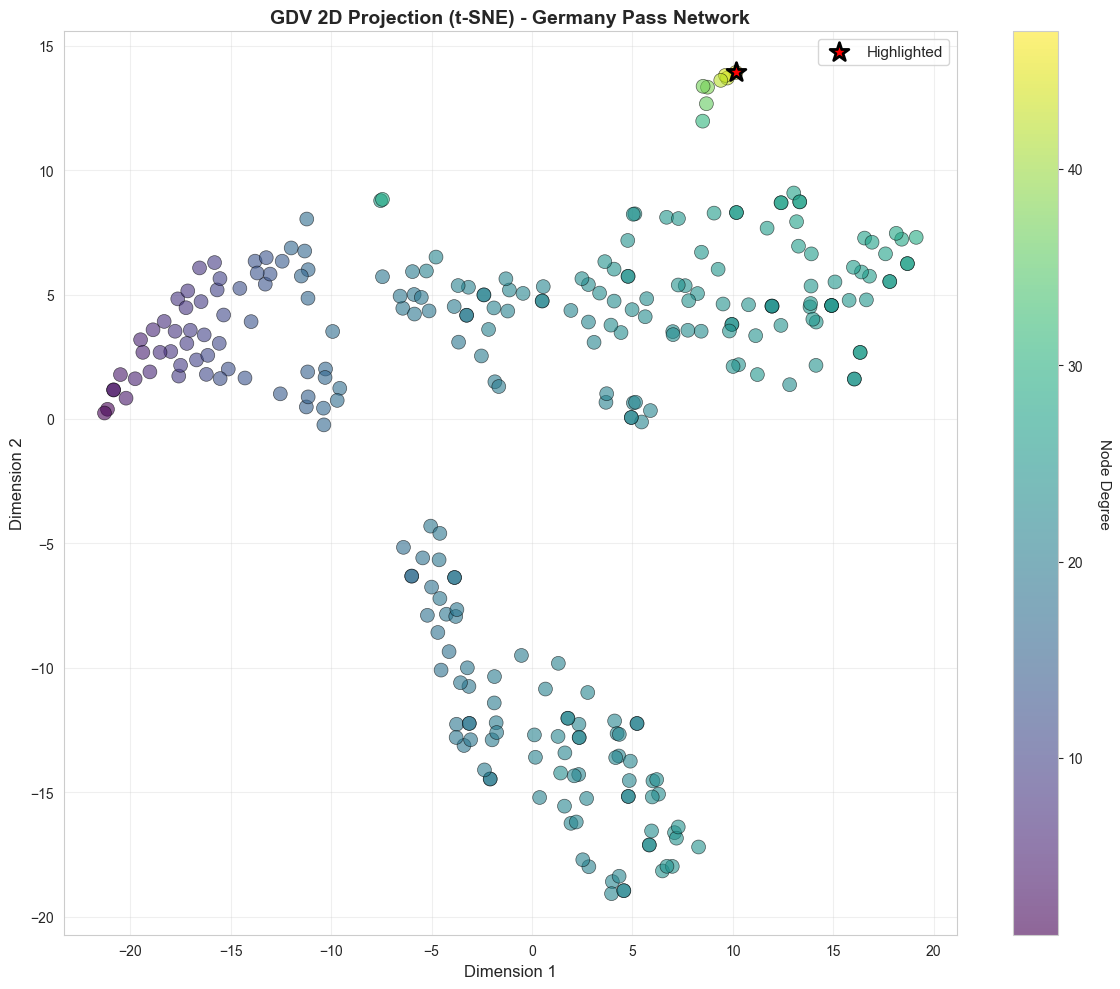

In [73]:
print("\n" + "=" * 70)
print("2D VISUALIZATION - t-SNE Projection")
print("=" * 70)

gdv_2d_germany = reduce_gdv_dimensions(gdv_germany_norm, method='tsne', random_state=42)

# Get top 10 nodes and print as table
top_10_nodes = [node for node, _ in degree_sorted[:10]]

print("\nTop 10 nodes (marked with stars in visualization):")
print(f"{'Rank':<6} {'Node Name':<25} {'Degree':<8} {'2D Position (x, y)':<25}")
for rank, (node, deg) in enumerate(degree_sorted[:10], 1):
    node_name = G_pass_gcc.nodes[node].get('label', str(node))
    x, y = gdv_2d_germany[node]
    print(f"{rank:<6} {node_name:<25} {deg:<8} ({x:>7.2f}, {y:>7.2f})")
    
# Get node labels for top nodes
top_10_nodes = [node for node, _ in degree_sorted[:10]]
node_labels_dict = {node: G_pass_gcc.nodes[node].get('label', str(node))[:8] 
                   for node in top_10_nodes}

fig_tsne = visualize_gdv_scatter(gdv_2d_germany, G_pass_gcc,
                                 title="GDV 2D Projection (t-SNE) - Germany Pass Network",
                                 highlight_nodes=[target_node])
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'gdv_tsne_germany.png',
            dpi=300, bbox_inches='tight')
plt.show()



- Nodes close together have similar local structure
- Color indicates degree (darker = higher degree)
- Clusters reveal groups with similar tactical roles

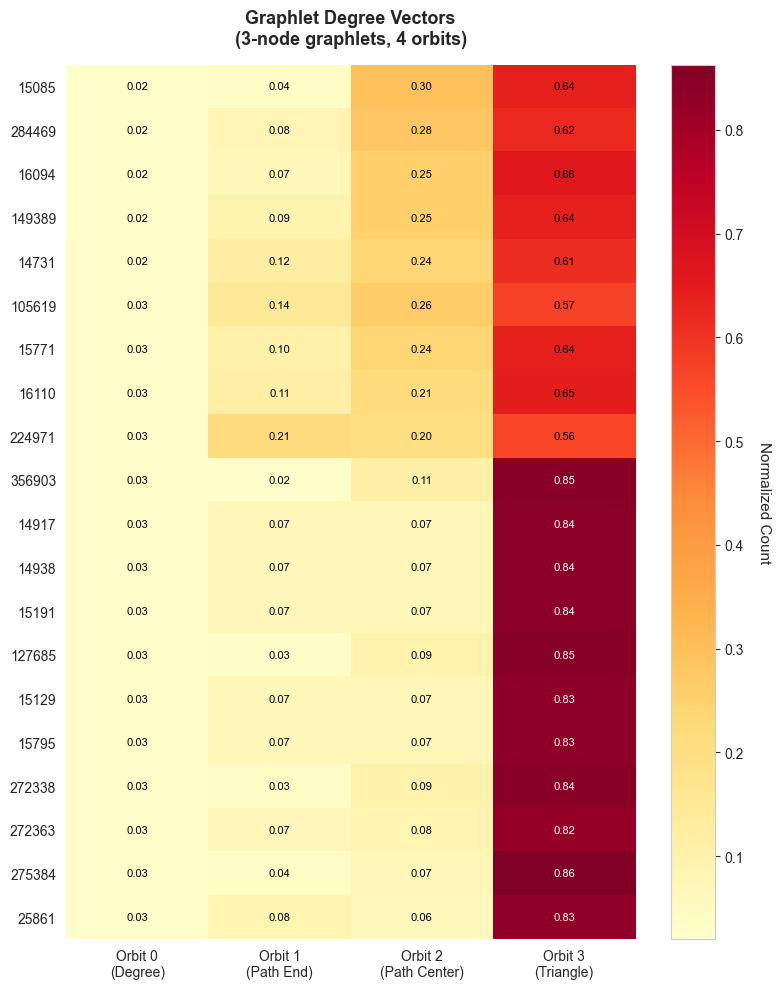

In [79]:
fig_heatmap = visualize_gdv_heatmap(gdv_germany, normalize=True)
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'gdv_heatmap_germany.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [75]:
print("\n" + "=" * 70)
print("GDV vs TRADITIONAL CENTRALITY")
print("=" * 70)

# Calculate centralities
degree_cent = dict(G_pass_gcc.degree())
betweenness_cent = nx.betweenness_centrality(G_pass_gcc)
closeness_cent = nx.closeness_centrality(G_pass_gcc)

# Compare top nodes
print("\nTop 5 by different metrics:")
print("\nBy Degree:")
for i, (node, val) in enumerate(sorted(degree_cent.items(), key=lambda x: x[1], reverse=True)[:5], 1):
    name = G_pass_gcc.nodes[node].get('label', str(node))[:20]
    vec = gdv_germany[node]
    print(f"{i}. {name:<20} Degree={val:<3} GDV={vec}")

print("\nBy Betweenness:")
for i, (node, val) in enumerate(sorted(betweenness_cent.items(), key=lambda x: x[1], reverse=True)[:5], 1):
    name = G_pass_gcc.nodes[node].get('label', str(node))[:20]
    vec = gdv_germany[node]
    print(f"{i}. {name:<20} Between={val:.4f} GDV={vec}")


GDV vs TRADITIONAL CENTRALITY

Top 5 by different metrics:

By Degree:
1. S. Wagner            Degree=47  GDV=[47, 84, 632, 1347]
2. J. Brekalo           Degree=44  GDV=[44, 159, 542, 1212]
3. S. Terodde           Degree=43  GDV=[43, 132, 483, 1260]
4. J. Toljan            Degree=42  GDV=[42, 160, 467, 1182]
5. M. Gómez             Degree=38  GDV=[38, 198, 379, 972]

By Betweenness:
1. J. Bruun Larsen      Between=0.4981 GDV=[16, 184, 28, 276]
2. S. Wagner            Between=0.3976 GDV=[47, 84, 632, 1347]
3. J. Toljan            Between=0.3262 GDV=[42, 160, 467, 1182]
4. M. Dahoud            Between=0.3112 GDV=[27, 64, 83, 804]
5. M. Friedl            Between=0.2882 GDV=[26, 229, 156, 507]



GDV ANALYSIS - France Pass Network

Calculating GDV for 215 nodes...
Calculating GDV for all nodes...

Node role distribution:
  Hub         : 40 nodes
  Bridge      : 0 nodes
  Peripheral  : 129 nodes
  Clustered   : 46 nodes
Reducing dimensions with t-SNE...

Top 10 nodes (marked with stars in visualization):
Rank   Node Name                 Degree   2D Position (x, y)       
1      N. de Préville            43       (  -1.25,    8.88)
2      R. Walter                 42       (  -1.34,    8.82)
3      I. Sacko                  39       (  -1.44,    8.72)
4      S. Meïté                  37       (  -1.90,    8.35)
5      João Moutinho             31       (   3.45,    9.19)
6      K. Mbappé                 30       (  -2.79,    7.10)
7      Xeka                      30       (  -2.74,    7.02)
8      Fabinho                   29       (   4.67,    8.21)
9      A. Saint-Maximin          29       (  -2.74,    6.92)
10     P. Lees Melou             29       (   4.18,    8.33)


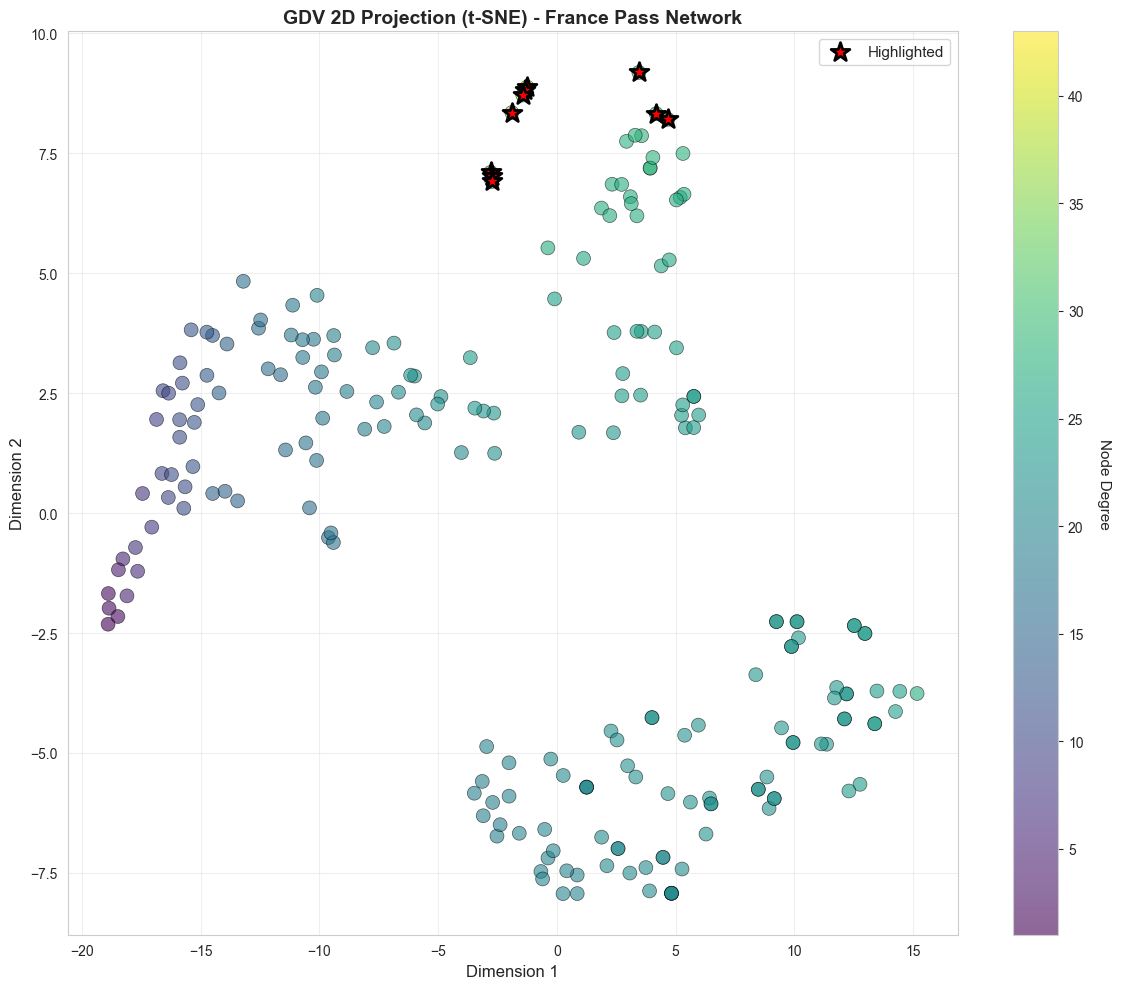

In [76]:
print("\n" + "=" * 70)
print("GDV ANALYSIS - France Pass Network")
print("=" * 70)

print(f"\nCalculating GDV for {F_pass_gcc.number_of_nodes()} nodes...")
gdv_france = calculate_gdv_3node(F_pass_gcc)
gdv_france_norm = normalize_gdv(gdv_france)

roles_france = analyze_node_roles(gdv_france, F_pass_gcc)

print("\nNode role distribution:")
for role, nodes in roles_france.items():
    print(f"  {role.capitalize():12}: {len(nodes)} nodes")

# 2D visualization
gdv_2d_france = reduce_gdv_dimensions(gdv_france_norm, method='tsne', random_state=42)

# Get top 10 nodes and print as table
degree_sorted_fr = sorted(F_pass_gcc.degree(), key=lambda x: x[1], reverse=True)[:10]
top_10_nodes_fr = [node for node, _ in degree_sorted_fr]

print("\nTop 10 nodes (marked with stars in visualization):")
print(f"{'Rank':<6} {'Node Name':<25} {'Degree':<8} {'2D Position (x, y)':<25}")
for rank, (node, deg) in enumerate(degree_sorted_fr[:10], 1):
    node_name = F_pass_gcc.nodes[node].get('label', str(node))
    x, y = gdv_2d_france[node]
    print(f"{rank:<6} {node_name:<25} {deg:<8} ({x:>7.2f}, {y:>7.2f})")

node_labels_fr = {node: F_pass_gcc.nodes[node].get('label', str(node))[:8] 
                 for node, _ in degree_sorted_fr}

fig_tsne_fr = visualize_gdv_scatter(gdv_2d_france, F_pass_gcc,
                                    title="GDV 2D Projection (t-SNE) - France Pass Network",
                                    highlight_nodes=top_10_nodes_fr)
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'gdv_tsne_france.png',
            dpi=300, bbox_inches='tight')
plt.show()


ROLE COMPARISON - Germany vs France


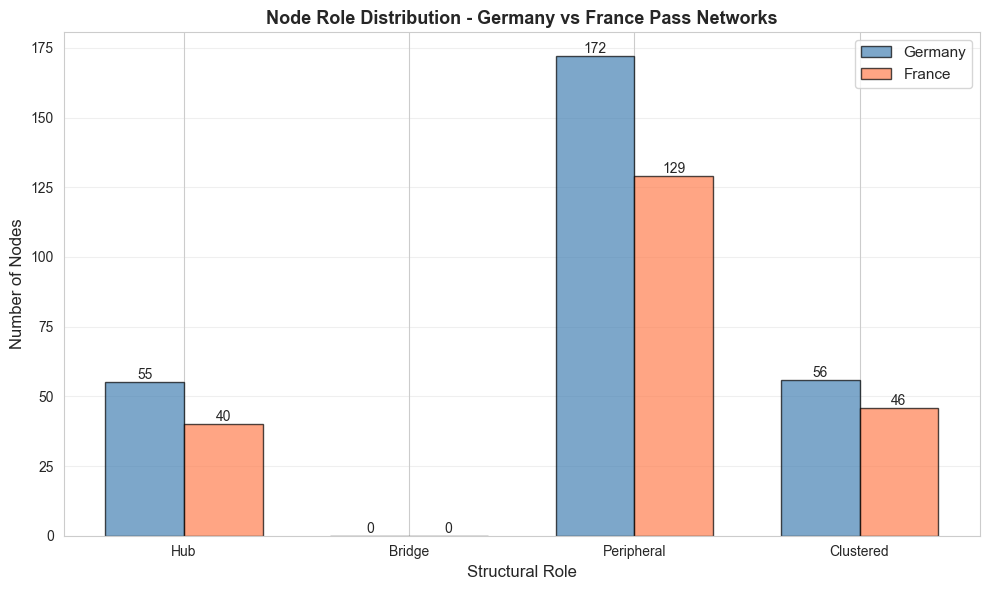

In [77]:
print("\n" + "=" * 70)
print("ROLE COMPARISON - Germany vs France")
print("=" * 70)

# Compare role distributions
fig, ax = plt.subplots(figsize=(10, 6))

roles_list = ['hub', 'bridge', 'peripheral', 'clustered']
germany_counts = [len(roles_germany[role]) for role in roles_list]
france_counts = [len(roles_france[role]) for role in roles_list]

x = np.arange(len(roles_list))
width = 0.35

ax.bar(x - width/2, germany_counts, width, label='Germany', 
       alpha=0.7, edgecolor='black', color='steelblue')
ax.bar(x + width/2, france_counts, width, label='France',
       alpha=0.7, edgecolor='black', color='coral')

ax.set_xlabel('Structural Role', fontsize=12)
ax.set_ylabel('Number of Nodes', fontsize=12)
ax.set_title('Node Role Distribution - Germany vs France Pass Networks',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([r.capitalize() for r in roles_list])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

# Add count labels
for i in range(len(roles_list)):
    ax.text(i - width/2, germany_counts[i], str(germany_counts[i]), 
           ha='center', va='bottom', fontsize=10)
    ax.text(i + width/2, france_counts[i], str(france_counts[i]), 
           ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE10' / 'gdv_roles_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Conclusion

Graphlets provide a powerful lens for analyzing football networks beyond traditional metrics. The near-identical RGFD between Germany and France (0.008) reveals that both nations employ remarkably similar tactical building blocks, despite differences in network size and individual players. The dominance of triangular patterns (G2: 60%) reflects modern possession-based football, while the lack of bridge nodes indicates cohesive, well-integrated team structures without isolated tactical units.